## Trying segmentation

In [8]:
import cv2
import numpy as np

def show_pieces(rgba, regions):
    """Each piece filled with its real average color, with dark borders between pieces."""
    rgb = rgba[..., :3].astype(float)
    n = regions.max() + 1
    counts = np.bincount(regions.ravel(), minlength=n)
    means = np.stack([np.bincount(regions.ravel(), rgb[..., c].ravel(), n) for c in range(3)], 1)
    means = (means / np.maximum(counts, 1)[:, None]).astype(np.uint8)
    means[0] = 255
    out = means[regions]
    edges = cv2.morphologyEx(regions.astype(np.uint16), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    out[edges] = (40, 40, 40)
    return out

18 pieces


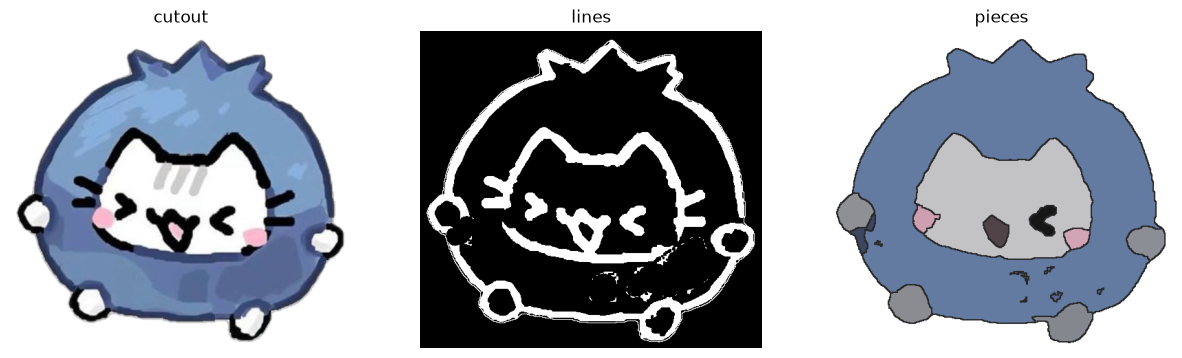

In [9]:
import importlib
import src.segmentation
importlib.reload(src.segmentation)
from src.segmentation import segment, colorize

rgba, _ = remove_background(load_rgb(DATA_2D / "medium" / "5m.jpg", 768))
regions, lines = segment(rgba)
print(regions.max(), "pieces")
show([rgba, lines, show_pieces(rgba, regions)], ["cutout", "lines", "pieces"])